# Evaluation.

The model is assessed by comparing the metrics against the baseline while verifying if the differences are stattistically meaningful.
The model is considered useful if the `RMSE` is lower then the baseline and `MDA` is higher than the baseline on the test set.
The model evaluation result will determine if it can be deployed or if we should go back and repeat the CRISP-DM cycle with new information.


In [2]:
from pathlib import Path
import json
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"

print("Project folder:", PROJECT_ROOT)
print("Models folder:", ARTIFACTS_DIR)

Project folder: /opt/aima-python/Stock_Price_DL
Models folder: /opt/aima-python/Stock_Price_DL/artifacts


Next: [`05_deployment_demo.ipynb`](05_deployment_demo.ipynb)

In [4]:
for model_name in ["model_b", "model_d", "model_f"]:
    metadata_file = ARTIFACTS_DIR / model_name / "metadata.json"

    with open(metadata_file, "r") as file:
        results = json.load(file)

    print(model_name)
    print("Validation MAE:", results.get("validation_mae"))
    print("Validation RMSE:", results.get("validation_rmse"))
    print()

model_b
Validation MAE: 0.014892838895320892
Validation RMSE: 0.019353807084020406

model_d
Validation MAE: 0.01387596782296896
Validation RMSE: 0.01859133639618466

model_f
Validation MAE: 0.01367315836250782
Validation RMSE: 0.018435376162920212



In [5]:
comparison = []

for model_name in ["model_b", "model_d", "model_f"]:
    metadata_file = ARTIFACTS_DIR / model_name / "metadata.json"

    with open(metadata_file, "r") as file:
        results = json.load(file)

    comparison.append({
        "Model": model_name.upper(),
        "Validation MAE": results["validation_mae"],
        "Validation RMSE": results["validation_rmse"]
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="Validation RMSE"
)

comparison_df

,Model,Validation MAE,Validation RMSE
2,MODEL_F,0.013673,0.018435
1,MODEL_D,0.013876,0.018591
0,MODEL_B,0.014893,0.019354


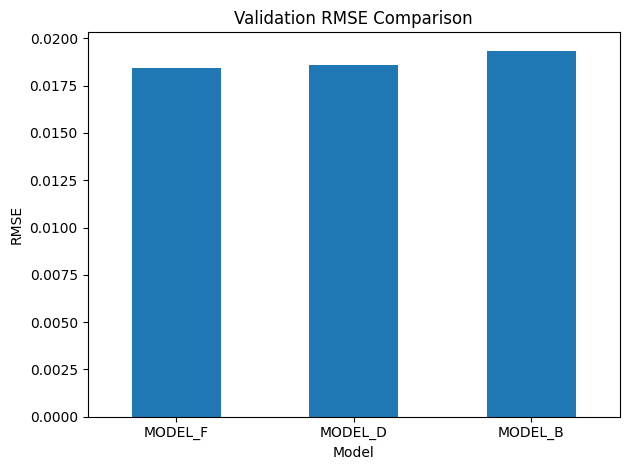

In [6]:
import matplotlib.pyplot as plt

comparison_df.plot(
    x="Model",
    y="Validation RMSE",
    kind="bar",
    legend=False
)

plt.title("Validation RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Evaluation Results – Models B, D, and F

Three deep learning models were evaluated to predict Apple's (AAPL)
next-day stock price changes using historical price and trading volume
information. These predictions can also be used to estimate the next
day's closing price.

The models included:

- Model B: LSTM with price and trading volume
- Model D: GRU with price and trading volume
- Model F: 1D-CNN with price and trading volume

Each model used information from the previous 60 trading days to
predict the next day's stock price change.

The models were compared using two measurements: Mean Absolute Error
(MAE) and Root Mean Squared Error (RMSE). Both measure prediction
errors, with lower values indicating better performance.

The validation results were:

- Model B (LSTM): MAE = 0.014893, RMSE = 0.019354
- Model D (GRU): MAE = 0.013876, RMSE = 0.018591
- Model F (1D-CNN): MAE = 0.013673, RMSE = 0.018435

Model F (1D-CNN) achieved the lowest validation MAE and RMSE, followed
by Model D (GRU) and Model B (LSTM).

These results suggest that Model F performed best among the three
models on the validation data.

The prediction errors represent differences in predicted logarithmic
returns, rather than dollar amounts.

However, additional comparisons with the price-only models (A, C, and
E) are needed to determine whether including trading volume improves
prediction accuracy.

Final testing will also be needed before drawing conclusions about
overall model performance.

Overall, Model F showed the strongest validation performance among the
three models evaluated.

In [7]:
metadata_file = ARTIFACTS_DIR / "model_f" / "metadata.json"

with open(metadata_file, "r") as file:
    metadata = json.load(file)

print(json.dumps(metadata, indent=4))

{
    "model": "1D-CNN",
    "run": "F",
    "features": [
        "log_return",
        "log_volume",
        "volume_change"
    ],
    "lookback": 60,
    "validation_mae": 0.01367315836250782,
    "validation_rmse": 0.018435376162920212
}


In [10]:
import sys
import inspect

sys.path.insert(0, str(PROJECT_ROOT))

from src import features

print(inspect.getsource(features.build_modeling_frame))

def build_modeling_frame(df: pd.DataFrame, ticker: str = config.TICKER) -> pd.DataFrame:
    """
    Full feature-engineering pipeline for TRAINING/EVALUATION:
    features + target, with incomplete rows removed.

    Removes the first row (no previous close -> no return) and the last row
    (no next day -> no target).
    """
    out = add_target(add_features(df), ticker)
    return out.dropna(subset=ENGINEERED_FEATURES + ["target"])



In [11]:
print(inspect.getsource(features.add_target))

def add_target(df: pd.DataFrame, ticker: str = config.TICKER) -> pd.DataFrame:
    """
    Add the prediction target for each row t, which describes day t+1.

    shift(-1) moves every value one row UP, so row t receives tomorrow's value.
    The last row gets NaN because its tomorrow is not in the data yet;
    that is the day to predict in deployment.

    Columns added
    -------------
    target      : what the network learns (next log return).
    next_close  : tomorrow's actual close (used to evaluate in dollars).
    target_date : tomorrow's date (used for plots).
    """
    out = df.copy()
    if isinstance(df.columns, pd.MultiIndex):
        out["next_close", ticker] = out["Close", ticker].shift(-1)
        out["target_date"] = out.index.to_series().shift(-1)
        out["target", ticker] = out["log_return", ticker].shift(-1)
    else:
        out["next_close"] = out["Close"].shift(-1)
        out["target_date"] = out.index.to_series().shift(-1)
        out["target"] = out["

In [14]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   04_evaluation.ipynb

no changes added to commit (use "git add" and/or "git commit -a")


In [15]:
!git switch -c Basma-evaluation

Switched to a new branch 'Basma-evaluation'


In [16]:
!git add notebooks/04_evaluation.ipynb

fatal: pathspec 'notebooks/04_evaluation.ipynb' did not match any files


!git add 04_evaluation.ipynb

In [17]:
!git add 04_evaluation.ipynb

/opt/venv/bin/python: No module named nbstripout
error: external filter '"/opt/venv/bin/python" -m nbstripout' failed 1
error: external filter '"/opt/venv/bin/python" -m nbstripout' failed
fatal: notebooks/04_evaluation.ipynb: clean filter 'nbstripout' failed


In [19]:
!git -c filter.nbstripout.clean=cat add 04_evaluation.ipynb

In [20]:
!git status

On branch Basma-evaluation
Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	modified:   04_evaluation.ipynb

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   04_evaluation.ipynb

